In [1]:
from ech_discovery.data.aggregates import common
from ech_discovery.notebook import *
from dataclasses import dataclass
from datetime import datetime, time
from typing import Callable

# Load data

In [2]:
input_stats = loader.ech_input_stats().filter(
    RANGES["main"].expr() | RANGES["followup"].expr()
)

In [3]:
df = loader.ech_stats().filter(RANGES["main"].expr() | RANGES["followup"].expr())
df.head().collect()

ech_public_name,measurement,role,location,ECH in DNS,target-sld,kind
str,datetime[μs],str,str,bool,u32,str
"""cover.todaypop.net""",2025-11-06 04:30:00,"""ech""","""africa-south1""",true,1,"""accepted"""
"""scontent.xx.fbcdn.net""",2025-11-06 04:30:00,"""ech""","""africa-south1""",false,1,"""accepted"""
"""scontent-lax3-2.xx.fbcdn.net""",2025-11-06 04:30:00,"""ech""","""africa-south1""",false,1,"""accepted"""
"""facebook.com""",2025-11-06 04:30:00,"""ech""","""africa-south1""",false,1,"""accepted"""
"""vidacristiana.info""",2025-11-06 04:30:00,"""ech""","""africa-south1""",false,1,"""accepted"""


In [4]:
def set_axis_ticks(ax, *, ylim, major, minor):
    ax.set(ylim=ylim)
    ax.yaxis.set_minor_locator(ticker.MultipleLocator(minor))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(major))


def filter_legend(handles, labels):
    filtered = [
        (h, l)
        for h, l in zip(handles, labels)
        if l
        not in [C.ech_public_name, C.role]
        + config.MAIN_ECH_PUBLIC_NAMES
        + [Strings.others]
    ]
    handles, labels = list(zip(*filtered)) if filtered else ([], [])
    return handles, labels


def plot_lines(
    df,
    ax,
    palette,
    *,
    y,
    hue,
    ylim,
    major,
    minor,
    legend=True,
    legend_loc="upper left",
    legend_ncol=2,
    style_order=None,
):
    if style_order is None:
        style_order = list(role_map.values())[:2]
    sns.lineplot(
        df.with_columns(pl.col(C.role).replace(role_map)),
        x=C.measurement,
        y=y,
        hue=hue,
        style=C.role,
        style_order=style_order,
        ax=ax,
        palette=palette,
    )
    handles, labels = filter_legend(*ax.get_legend_handles_labels())
    for handle in handles:
        handle.set_color(palette[0])
    if legend:
        ax.legend(
            handles,
            labels,
            ncol=legend_ncol,
            loc=legend_loc,
            columnspacing=1.0,
            handletextpad=0.5,
            borderpad=0.4,
            borderaxespad=0.2,
        )
    else:
        ax.legend().remove()
    set_axis_ticks(ax, ylim=ylim, major=major, minor=minor)


def _drop_ticks_near_edge(ax, edge, frac=0.06):
    xmin, xmax = ax.get_xlim()
    span = xmax - xmin
    ticks = ax.get_xticks()
    if edge == "right":
        keep = [t for t in ticks if t < xmax - frac * span]
    else:
        keep = [t for t in ticks if t > xmin + frac * span]
    ax.set_xticks(keep)

In [5]:
@dataclass
class RowSpec:
    title: str
    plot: Callable[..., None]  # plot(ax) draws the row's data onto a single axes
    legend_col: int = 0  # which column keeps its legend (0 = main, 1 = followup)


COLUMN_TIME_SETTINGS = {
    "main": dict(
        major=mdates.DayLocator(interval=28),
        minor=mdates.DayLocator(interval=7),
        fmt="%Y\n%m-%d",
    ),
    "followup": dict(
        major=mdates.DayLocator(interval=28),
        minor=mdates.DayLocator(interval=7),
        fmt="%Y\n%m-%d",
    ),
}


def render_broken_row(fig, ax_main, ax_follow, spec: RowSpec, ranges):
    spec.plot(ax_main)
    spec.plot(ax_follow)

    drop = ax_follow if spec.legend_col == 0 else ax_main
    if (leg := drop.get_legend()) is not None:
        leg.remove()

    for ax, key in ((ax_main, "main"), (ax_follow, "followup")):
        settings = COLUMN_TIME_SETTINGS[key]
        ax.set_xlim(
            datetime.combine(ranges[key].start, time()),
            datetime.combine(ranges[key].end, time()),
        )
        ax.yaxis.set_major_formatter(ticker.EngFormatter())
        if ax == ax_follow:
            ax.tick_params(
                axis="y", which="minor", left=False, right=False, labelleft=False
            )
        ax.xaxis.set_major_locator(settings["major"])

        ax.xaxis.set_minor_locator(settings["minor"])
        _drop_ticks_near_edge(ax_main, "right")
        _drop_ticks_near_edge(ax_follow, "left")
        vh.set_time_format(
            ax.xaxis, settings["fmt"], C.measurement, Strings.measurement_start_time
        )
        ax.set(xlabel=None, ylabel=None)

    vh.mark_axis_break(ax_main, ax_follow)
    vh.row_title(fig, ax_main, ax_follow, spec.title)


/mnt/data01/artifacts-active-ech/06-ech-analysis/reports/figures/ech-deployments-time/lin_ech_deployment_others.png


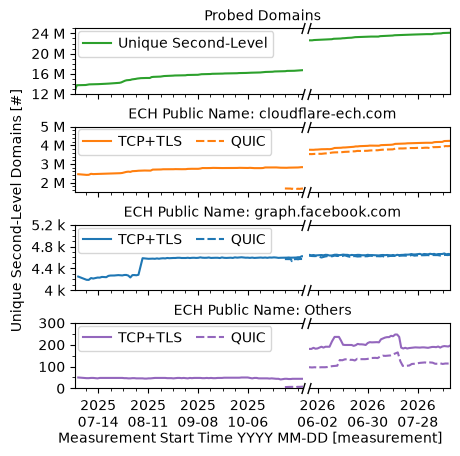

In [6]:
data = (
    input_stats.filter(pl.col(C.location) == "tud", pl.col(C.role) == "ech")
    .with_columns(pl.col(C.measurement).dt.date())
    .with_columns(pl.lit(Strings.unique_second_level).alias(C.role))
    .collect()
)

rows = [
    RowSpec(
        title=Strings.probed_domains,
        plot=lambda ax: plot_lines(
            data,
            ax,
            sns.color_palette("tab10")[2:3],
            y=C.target_sld_total,
            hue=C.role,
            ylim=(12_000_000, 25_000_000),
            major=4_000_000,
            minor=1_000_000,
            style_order=[Strings.unique_second_level],
        ),
    ),
    RowSpec(
        title=f"{Strings.ech_public_name}: {config.PUBLIC_NAME_CLOUDFLARE}",
        plot=lambda ax: plot_lines(
            df.filter(
                pl.col(C.ech_public_name) == config.PUBLIC_NAME_CLOUDFLARE,
                pl.col(C.location) == "tud",
            )
            .collect()
            .group_by(C.measurement, C.role, C.location, C.ech_public_name)
            .agg(pl.col(C.target_sld).sum()),
            ax,
            sns.color_palette("tab10")[1:2],
            y=C.target_sld,
            hue=C.ech_public_name,
            ylim=(1_500_000, 5_000_000),
            major=1_000_000,
            minor=200_000,
        ),
    ),
    RowSpec(
        title=f"{Strings.ech_public_name}: {config.PUBLIC_NAME_META}",
        plot=lambda ax: plot_lines(
            df.filter(
                pl.col(C.ech_public_name) == config.PUBLIC_NAME_META,
                pl.col(C.location) == "tud",
            )
            .collect()
            .group_by(C.measurement, C.role, C.location, C.ech_public_name)
            .agg(pl.col(C.target_sld).sum()),
            ax,
            sns.color_palette("tab10")[0:1],
            y=C.target_sld,
            hue=C.ech_public_name,
            ylim=(4_000, 5_200),
            major=400,
            minor=100,
        ),
    ),
    RowSpec(
        title=f"{Strings.ech_public_name}: {Strings.others}",
        plot=lambda ax: plot_lines(
            df.filter(
                ~pl.col(C.ech_public_name).is_in(config.MAIN_ECH_PUBLIC_NAMES),
                pl.col(C.location) == "tud",
            )
            .collect()
            .group_by(C.measurement, C.role, C.location)
            .agg(
                pl.col(C.target_sld).sum(),
                pl.lit(Strings.others).alias(C.ech_public_name),
            ),
            ax,
            sns.color_palette("tab10")[4:5],
            y=C.target_sld,
            hue=C.ech_public_name,
            ylim=(0, 300),
            major=100,
            minor=50,
        ),
    ),
]

fig, axs = vh.fig_ax(
    (5, 1.2 * len(rows)),
    nrows=len(rows),
    ncols=2,
    sharex="col",
    sharey="row",
    gridspec_kw={
        "hspace": 0.5,
        "wspace": 0.03,
        "bottom": 0.13,
        "left": 0.15,
        "width_ratios": [
            RANGES["main"].duration.days / RANGES["followup"].duration.days,
            1,
        ],
    },
    squeeze=False, 
)

for spec, (ax_main, ax_follow) in zip(rows, axs):
    render_broken_row(fig, ax_main, ax_follow, spec, RANGES)

fig.supxlabel(
    f"{Strings.measurement_start_time} YYYY MM-DD [measurement]",
    fontsize=plt.rcParams["axes.labelsize"],
)
fig.supylabel(
    f"Unique Second-Level Domains [#]",
    fontsize=plt.rcParams["axes.labelsize"],
)
vh.save_plot(
    fig,
    "lin_ech_deployment_others",
    directory=config.FIGURES_DIR / "ech-deployments-time",
)